# TelcoPeople — EDA, préparation et première baseline CatBoost

Ce notebook construit une première solution complète pour prédire le départ d’un collaborateur dans les six mois suivant la date de référence.

Le travail suit cinq étapes :

1. charger et comprendre les données ;
2. contrôler leur qualité ;
3. analyser les principaux facteurs associés au départ ;
4. créer des variables métier reproductibles ;
5. entraîner et évaluer un modèle avec une validation temporelle adaptée au test.

**Métrique principale : F1-score de la classe `target = 1`.**

## 1. Importation des bibliothèques

La cellule suivante importe les bibliothèques utilisées pour la manipulation des données, la visualisation et la modélisation.

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from catboost import CatBoostClassifier

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

## 2. Chargement des fichiers

Le notebook étant placé dans le dossier `notebooks`, le chemin `../data/raw/` permet d’accéder aux fichiers bruts situés à la racine du projet.

In [4]:
CHEMIN_DONNEES = "../data/raw/"

train = pd.read_csv(CHEMIN_DONNEES + "telcopeople_train.csv")
test = pd.read_csv(CHEMIN_DONNEES + "telcopeople_test.csv")
dictionnaire = pd.read_csv(CHEMIN_DONNEES + "telcopeople_data_dictionary.csv")

print("Train :", train.shape)
print("Test :", test.shape)
print("Dictionnaire :", dictionnaire.shape)

Train : (5444, 42)
Test : (1507, 41)
Dictionnaire : (85, 3)


## 3. Compréhension générale des données

Chaque ligne correspond à une observation RH réalisée à une date de référence. La cible `target` vaut `1` lorsque le collaborateur part dans les six mois suivants et `0` sinon.

In [5]:
print("Colonnes uniquement présentes dans le train :", set(train.columns) - set(test.columns))
print("Nombre de doublons complets :", train.duplicated().sum())
print("Nombre d'identifiants dupliqués :", train["id"].duplicated().sum())

display(train.head())
display(dictionnaire.head(20))

Colonnes uniquement présentes dans le train : {'target'}
Nombre de doublons complets : 0
Nombre d'identifiants dupliqués : 0


,id,date_reference,genre,date_naissance,ville_affectation,departement,poste,niveau_etude,contrat,grade,date_embauche,date_derniere_promotion,salaire_mensuel,salaire_12m_avant,reference_salaire_grade,performance_actuelle,performance_precedente,engagement_actuel,engagement_precedent,date_derniere_absence,jours_abs_m1,jours_abs_m2,jours_abs_m3,jours_abs_m4,jours_abs_m5,jours_abs_m6,abs_non_just_m1,abs_non_just_m2,abs_non_just_m3,abs_non_just_m4,abs_non_just_m5,abs_non_just_m6,nb_abs_m1,nb_abs_m2,nb_abs_m3,nb_abs_m4,nb_abs_m5,nb_abs_m6,taille_departement,code_site,source_sirh,target
0,OBS000001,2022-06-30,M,1987-08-18,Abidjan,DEP06,HR Business Partner,Bac+2,CDI,G2,2021-12-29,NaN,570000,NaN,560000.0,3.58,NaN,3.15,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,40,INT,PAYROLL_SYNC,0
1,OBS000002,2022-06-30,M,1983-03-08,Abidjan,DEP08,Développeur,Bac+2,CDI,G2,2021-09-29,NaN,645000,NaN,618000.0,3.09,NaN,2.85,NaN,2022-05-23,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,64,ABJ-TRV,HR_CORE,0
2,OBS000003,2022-06-30,M,1975-10-25,Korhogo,DEP02,Analyste Ventes,Bac+5,CDI,G4,2016-11-29,2019-10-30,1035000,987000.0,1092000.0,4.64,4.61,4.22,4.131507,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,178,INT,PAYROLL_SYNC,1
3,OBS000004,2022-06-30,F,1980-05-15,Abidjan,DEP10,Logisticien,Bac+3,CDI,G3,2018-03-31,NaN,665000,632000.0,920000.0,3.13,3.24,3.54,3.882506,2022-06-09,4,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,45,ABJ-COC,HR_CORE,1
4,OBS000005,2022-06-30,F,1983-12-05,Abidjan,DEP04,Conseiller Client,Bac+5,CDI,G2,2020-05-30,NaN,560000,535000.0,519000.0,3.18,3.65,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,216,INT,PAYROLL_SYNC,0


,fichier,colonne,description
0,telcopeople_train_v3.csv,id,Identifiant unique de l'observation.
1,telcopeople_train_v3.csv,date_reference,Date de référence de l'observation.
2,telcopeople_train_v3.csv,genre,Genre déclaré dans le SIRH.
3,telcopeople_train_v3.csv,date_naissance,Date de naissance enregistrée.
4,telcopeople_train_v3.csv,ville_affectation,Ville principale d'affectation.
5,telcopeople_train_v3.csv,departement,Code du département enregistré dans le SIRH.
6,telcopeople_train_v3.csv,poste,Intitulé du poste.
7,telcopeople_train_v3.csv,niveau_etude,Niveau d'études enregistré.
8,telcopeople_train_v3.csv,contrat,Type de contrat enregistré.
9,telcopeople_train_v3.csv,grade,Grade professionnel.


## 4. Répartition de la cible

Cette analyse mesure le déséquilibre entre les départs et les non-départs. Une classe minoritaire importante implique que l’accuracy seule ne convient pas. Le F1-score sera privilégié.

,effectif,pourcentage
target,,
0,4892,89.86
1,552,10.14


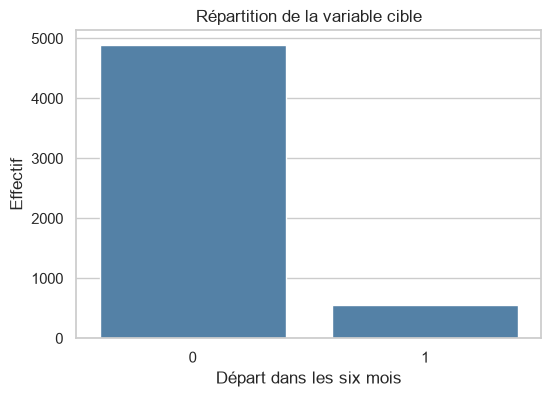

In [6]:
repartition_cible = pd.DataFrame({
    "effectif": train["target"].value_counts(),
    "pourcentage": train["target"].value_counts(normalize=True).mul(100).round(2)
})

display(repartition_cible)

plt.figure(figsize=(6, 4))
sns.countplot(data=train, x="target", color="steelblue")
plt.title("Répartition de la variable cible")
plt.xlabel("Départ dans les six mois")
plt.ylabel("Effectif")
plt.show()

## 5. Audit des types et des valeurs manquantes

La cellule suivante recense le type, le nombre de valeurs uniques et le taux de valeurs manquantes de chaque colonne.

In [7]:
audit = pd.DataFrame({
    "type": train.dtypes.astype(str),
    "valeurs_uniques": train.nunique(dropna=False),
    "valeurs_manquantes": train.isna().sum(),
    "taux_manquant_pct": train.isna().mean().mul(100).round(2)
})

display(audit.sort_values("taux_manquant_pct", ascending=False))

,type,valeurs_uniques,valeurs_manquantes,taux_manquant_pct
date_derniere_promotion,str,143,4494,82.55
date_derniere_absence,str,641,3059,56.19
engagement_precedent,float64,3552,1797,33.01
performance_precedente,float64,511,1608,29.54
salaire_12m_avant,float64,1245,1460,26.82
performance_actuelle,float64,303,706,12.97
engagement_actuel,float64,334,568,10.43
reference_salaire_grade,float64,1354,65,1.19
niveau_etude,str,9,65,1.19
genre,str,3,44,0.81


## 6. Qualité des variables catégorielles

Plusieurs catégories contiennent des variantes d’écriture, par exemple `CDI` et `C.D.I`, ou `DEP04` et `DEPT04`. Ces variantes seront harmonisées dans la fonction de préparation.

In [8]:
colonnes_a_controler = [
    "genre", "ville_affectation", "departement",
    "niveau_etude", "contrat", "grade",
    "code_site", "source_sirh"
]

for colonne in colonnes_a_controler:
    print(f"\n--- {colonne} ---")
    display(train[colonne].value_counts(dropna=False).head(20))


--- genre ---


genre
M      2854
F      2546
NaN      44
Name: count, dtype: int64


--- ville_affectation ---


ville_affectation
Abidjan           3852
Bouaké             474
Yamoussoukro       436
San-Pédro          324
Korhogo            260
 Abidjan            37
ABIDJAN             30
BOUAKÉ               8
 Bouaké              6
SAN-PÉDRO            5
KORHOGO              4
YAMOUSSOUKRO         3
 Yamoussoukro        2
 Korhogo             2
 San-Pédro           1
Name: count, dtype: int64


--- departement ---


...

grade
G2    1688
G3    1386
G1    1309
G4     715
G5     346
Name: count, dtype: int64


--- code_site ---


code_site
ABJ-PLT    1611
ABJ-COC    1283
ABJ-MAR    1079
ABJ-TRV     850
INT         621
Name: count, dtype: int64


--- source_sirh ---


source_sirh
HR_CORE         3945
PAYROLL_SYNC    1190
LEGACY           309
Name: count, dtype: int64

## 7. Contrôle des dates

Les dates utilisent plusieurs formats. `format="mixed"` permet de lire les formats `AAAA-MM-JJ` et `JJ/MM/AAAA`. La cellule vérifie aussi les dates d’embauche postérieures à la date de référence.

In [9]:
colonnes_dates = [
    "date_reference",
    "date_naissance",
    "date_embauche",
    "date_derniere_promotion",
    "date_derniere_absence"
]

dates_converties = {}

for colonne in colonnes_dates:
    dates_converties[colonne] = pd.to_datetime(
        train[colonne],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )
    print(
        colonne,
        "| valeurs invalides ou manquantes :",
        dates_converties[colonne].isna().sum()
    )

nombre_embauches_futures = (
    dates_converties["date_embauche"] > dates_converties["date_reference"]
).sum()

print("Embauches postérieures à la date de référence :", nombre_embauches_futures)

date_reference | valeurs invalides ou manquantes : 0
date_naissance | valeurs invalides ou manquantes : 0
date_embauche | valeurs invalides ou manquantes : 0
date_derniere_promotion | valeurs invalides ou manquantes : 4494
date_derniere_absence | valeurs invalides ou manquantes : 3059
Embauches postérieures à la date de référence : 11


## 8. Structure temporelle du challenge

Le train couvre plusieurs dates historiques alors que le test correspond à une période future. Une séparation aléatoire ne reproduit donc pas fidèlement la situation de compétition. La dernière période connue du train sera utilisée comme validation temporelle.

In [10]:
resume_periodes = train.groupby("date_reference")["target"].agg(
    effectif="count",
    departs="sum",
    taux_depart="mean"
)
resume_periodes["taux_depart"] = resume_periodes["taux_depart"].mul(100).round(2)

display(resume_periodes)

print("Périodes du test :")
display(test["date_reference"].value_counts().sort_index())

,effectif,departs,taux_depart
date_reference,,,
2022-06-30,873,87,9.97
2022-12-31,985,100,10.15
2023-06-30,1083,106,9.79
2023-12-31,1189,130,10.93
2024-06-30,1314,129,9.82


Périodes du test :


date_reference
2024-12-31    1507
Name: count, dtype: int64

## 9. Nettoyage du salaire et contrôle des valeurs extrêmes

Le salaire mensuel est stocké sous forme de texte dans certaines lignes. Il est converti en valeur numérique avant l’analyse.

In [11]:
salaire_numerique = pd.to_numeric(
    train["salaire_mensuel"]
        .astype(str)
        .str.replace("FCFA", "", regex=False)
        .str.replace(" ", "", regex=False),
    errors="coerce"
)

display(salaire_numerique.describe(percentiles=[0.01, 0.05, 0.95, 0.99]))

anomalies_salaire = train.loc[
    (salaire_numerique <= 0) | (salaire_numerique > 5_000_000),
    ["id", "poste", "grade", "salaire_mensuel", "reference_salaire_grade"]
].copy()

anomalies_salaire["salaire_mensuel_num"] = salaire_numerique.loc[anomalies_salaire.index]
display(anomalies_salaire.sort_values("salaire_mensuel_num"))

count    5.443000e+03
mean     7.797106e+05
std      6.087109e+05
min      0.000000e+00
1%       2.850000e+05
5%       3.350000e+05
95%      1.784500e+06
99%      2.639500e+06
max      1.925000e+07
Name: salaire_mensuel, dtype: float64

,id,poste,grade,salaire_mensuel,reference_salaire_grade,salaire_mensuel_num
610,OBS000611,Superviseur Centre de Contacts,G2,0,498000.0,0.0
902,OBS000903,Développeur,G1,0,421000.0,0.0
1985,OBS001986,Analyste CX,G3,0,753000.0,0.0
4964,OBS004965,Chargé Grands Comptes,G4,0,1131000.0,0.0
3060,OBS003061,Data Analyst,G2,0,642000.0,0.0
2830,OBS002831,Analyste CX,G3,0,763000.0,0.0
2463,OBS002464,Logisticien,G2,0,528000.0,0.0
2149,OBS002150,Conseiller Client,G2,0,566000.0,0.0
5294,OBS005295,Manager Technique,G5,0,1633000.0,0.0
3237,OBS003238,Conseiller Client,G1,0,328000.0,0.0


## 10. Analyse de l’attrition par catégorie

Les taux sont calculés avec les catégories brutes pour repérer les premiers écarts. Les conclusions définitives seront réalisées après harmonisation.

In [12]:
for colonne in ["genre", "contrat", "grade", "departement", "poste", "source_sirh"]:
    resultat = train.groupby(colonne, dropna=False)["target"].agg(
        effectif="count",
        departs="sum",
        taux_depart="mean"
    )
    resultat["taux_depart"] = resultat["taux_depart"].mul(100).round(2)

    print(f"\n--- {colonne} ---")
    display(resultat.sort_values(["taux_depart", "effectif"], ascending=[False, False]).head(15))


--- genre ---


,effectif,departs,taux_depart
genre,,,
F,2546,262,10.29
M,2854,286,10.02
NaN,44,4,9.09



--- contrat ---


,effectif,departs,taux_depart
contrat,,,
CDD,867,106,12.23
CDI,4495,445,9.90
C.D.I,70,1,1.43
cdd,12,0,0.00



--- grade ---


...

,effectif,departs,taux_depart
departement,,,
DEPT03,5,2,40.00
DEP10,248,36,14.52
NaN,33,4,12.12
DEP08,408,45,11.03
DEP06,245,27,11.02
DEP04,1366,147,10.76
DEP02,1082,115,10.63
DEP03,1042,107,10.27
DEP07,360,32,8.89



--- poste ---


,effectif,departs,taux_depart
poste,,,
Directeur,2,1,50.00
Manager Achats,44,9,20.45
Logisticien,73,13,17.81
Développeur,139,24,17.27
HR Business Partner,71,12,16.90
Digital Marketer,94,12,12.77
Analyste Marketing,40,5,12.50
Superviseur Centre de Contacts,457,57,12.47
Technicien Réseau,437,50,11.44



--- source_sirh ---


,effectif,departs,taux_depart
source_sirh,,,
LEGACY,309,42,13.59
HR_CORE,3945,393,9.96
PAYROLL_SYNC,1190,117,9.83


## 11. Engagement et départ

L’engagement est regroupé en classes pour vérifier si la baisse de l’engagement est associée à une hausse du taux de départ.

,effectif,departs,taux_depart
niveau_engagement,,,
Très faible,52,17,32.69
Faible,984,188,19.11
Moyen,2649,232,8.76
Élevé,1191,49,4.11


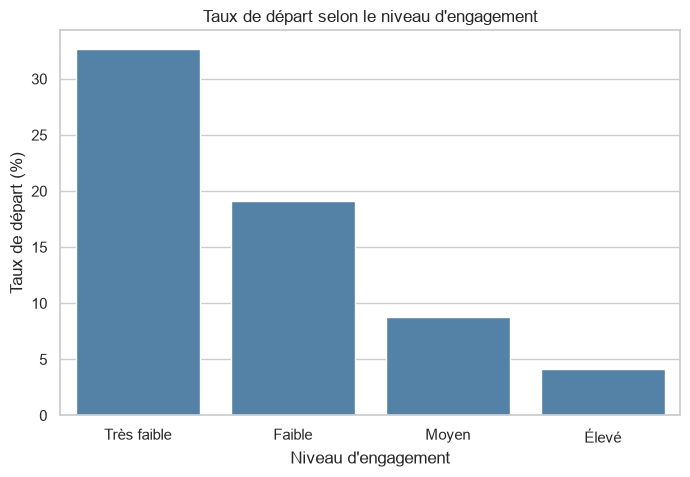

In [13]:
donnees_eda = train.copy()

donnees_eda["niveau_engagement"] = pd.cut(
    donnees_eda["engagement_actuel"],
    bins=[0, 2, 3, 4, 5],
    labels=["Très faible", "Faible", "Moyen", "Élevé"],
    include_lowest=True
)

analyse_engagement = donnees_eda.groupby(
    "niveau_engagement", observed=False
)["target"].agg(
    effectif="count",
    departs="sum",
    taux_depart="mean"
)
analyse_engagement["taux_depart"] = analyse_engagement["taux_depart"].mul(100).round(2)

display(analyse_engagement)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=analyse_engagement.reset_index(),
    x="niveau_engagement",
    y="taux_depart",
    color="steelblue"
)
plt.title("Taux de départ selon le niveau d'engagement")
plt.xlabel("Niveau d'engagement")
plt.ylabel("Taux de départ (%)")
plt.show()

## 12. Absentéisme et départ

Les jours d’absence des six derniers mois sont additionnés. L’objectif est de vérifier si un absentéisme plus élevé est associé à davantage de départs.

,effectif,departs,taux_depart
niveau_absence,,,
Aucune,3054,263,8.61
1 à 2 jours,1168,132,11.30
3 à 5 jours,744,87,11.69
Plus de 5 jours,478,70,14.64


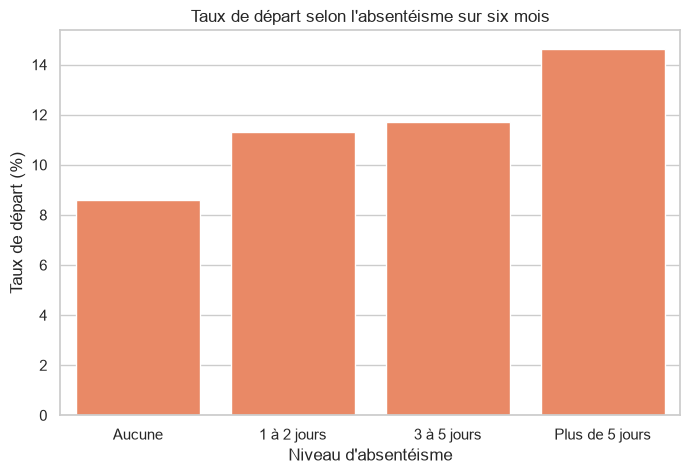

In [14]:
colonnes_jours_absence = [f"jours_abs_m{i}" for i in range(1, 7)]
donnees_eda["jours_abs_6m"] = donnees_eda[colonnes_jours_absence].sum(axis=1)

donnees_eda["niveau_absence"] = pd.cut(
    donnees_eda["jours_abs_6m"],
    bins=[-1, 0, 2, 5, float("inf")],
    labels=["Aucune", "1 à 2 jours", "3 à 5 jours", "Plus de 5 jours"]
)

analyse_absence = donnees_eda.groupby(
    "niveau_absence", observed=False
)["target"].agg(
    effectif="count",
    departs="sum",
    taux_depart="mean"
)
analyse_absence["taux_depart"] = analyse_absence["taux_depart"].mul(100).round(2)

display(analyse_absence)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=analyse_absence.reset_index(),
    x="niveau_absence",
    y="taux_depart",
    color="coral"
)
plt.title("Taux de départ selon l'absentéisme sur six mois")
plt.xlabel("Niveau d'absentéisme")
plt.ylabel("Taux de départ (%)")
plt.show()

## 13. Fonction commune de préparation

La fonction suivante applique exactement les mêmes transformations au train et au test. Elle nettoie les catégories, convertit les dates et crée des variables métier liées à l’âge, l’ancienneté, la rémunération, l’engagement et l’absentéisme.

In [15]:
def preparer_donnees(df):
    df = df.copy()

    # Harmonisation des catégories
    df["ville_affectation"] = (
        df["ville_affectation"].fillna("INCONNU").str.strip().str.title()
    )
    df["departement"] = (
        df["departement"].fillna("INCONNU").str.strip().str.upper()
        .str.replace("DEPT", "DEP", regex=False)
    )
    df["contrat"] = (
        df["contrat"].fillna("INCONNU").str.strip().str.upper()
        .str.replace(".", "", regex=False)
    )
    df["niveau_etude"] = (
        df["niveau_etude"].fillna("INCONNU").str.strip().str.upper()
        .str.replace(" ", "", regex=False)
        .str.replace("BAC2", "BAC+2", regex=False)
    )

    autres_categories = ["genre", "poste", "grade", "code_site", "source_sirh"]
    for colonne in autres_categories:
        df[colonne] = df[colonne].fillna("INCONNU").astype(str).str.strip().str.upper()

    # Conversion des dates
    colonnes_dates = [
        "date_reference", "date_naissance", "date_embauche",
        "date_derniere_promotion", "date_derniere_absence"
    ]
    for colonne in colonnes_dates:
        df[colonne] = pd.to_datetime(
            df[colonne], format="mixed", dayfirst=True, errors="coerce"
        )

    # Conversion du salaire mensuel
    df["salaire_mensuel"] = pd.to_numeric(
        df["salaire_mensuel"].astype(str)
        .str.replace("FCFA", "", regex=False)
        .str.replace(" ", "", regex=False),
        errors="coerce"
    )

    # Variables temporelles
    df["age"] = (df["date_reference"] - df["date_naissance"]).dt.days / 365.25
    df["anciennete"] = (df["date_reference"] - df["date_embauche"]).dt.days / 365.25
    df["annees_depuis_promotion"] = (
        df["date_reference"] - df["date_derniere_promotion"]
    ).dt.days / 365.25
    df["jours_depuis_absence"] = (
        df["date_reference"] - df["date_derniere_absence"]
    ).dt.days
    df["annee_reference"] = df["date_reference"].dt.year
    df["mois_reference"] = df["date_reference"].dt.month

    # Indicateurs de données absentes ou incohérentes
    df["jamais_promu"] = df["date_derniere_promotion"].isna().astype(int)
    df["absence_recente_non_renseignee"] = df["date_derniere_absence"].isna().astype(int)
    df["engagement_actuel_manquant"] = df["engagement_actuel"].isna().astype(int)
    df["engagement_precedent_manquant"] = df["engagement_precedent"].isna().astype(int)
    df["performance_actuelle_manquante"] = df["performance_actuelle"].isna().astype(int)
    df["performance_precedente_manquante"] = df["performance_precedente"].isna().astype(int)
    df["anciennete_invalide"] = (df["anciennete"] < 0).astype(int)

    # Variables salariales
    df["ratio_salaire_reference"] = (
        df["salaire_mensuel"] / df["reference_salaire_grade"]
    )
    df["evolution_salaire"] = (
        df["salaire_mensuel"] - df["salaire_12m_avant"]
    )
    df["taux_evolution_salaire"] = (
        df["evolution_salaire"] /
        df["salaire_12m_avant"].replace(0, np.nan)
    )
    df["salaire_anormal"] = (
        (df["salaire_mensuel"] <= 0) |
        (df["ratio_salaire_reference"] < 0.5) |
        (df["ratio_salaire_reference"] > 2)
    ).astype(int)

    # Engagement et performance
    df["evolution_engagement"] = (
        df["engagement_actuel"] - df["engagement_precedent"]
    )
    df["evolution_performance"] = (
        df["performance_actuelle"] - df["performance_precedente"]
    )

    # Absentéisme cumulé sur six mois
    df["jours_abs_6m"] = df[
        [f"jours_abs_m{i}" for i in range(1, 7)]
    ].sum(axis=1)
    df["abs_non_just_6m"] = df[
        [f"abs_non_just_m{i}" for i in range(1, 7)]
    ].sum(axis=1)
    df["nb_abs_6m"] = df[
        [f"nb_abs_m{i}" for i in range(1, 7)]
    ].sum(axis=1)

    # Comparaison absentéisme récent et ancien
    df["jours_abs_recents"] = df[
        ["jours_abs_m1", "jours_abs_m2", "jours_abs_m3"]
    ].sum(axis=1)
    df["jours_abs_anciens"] = df[
        ["jours_abs_m4", "jours_abs_m5", "jours_abs_m6"]
    ].sum(axis=1)
    df["tendance_absence"] = (
        df["jours_abs_recents"] - df["jours_abs_anciens"]
    )

    return df

## 14. Application de la préparation au train et au test

Cette cellule applique la fonction aux deux jeux de données et vérifie que les colonnes explicatives restent alignées.

In [16]:
train_prepare = preparer_donnees(train)
test_prepare = preparer_donnees(test)

print("Train préparé :", train_prepare.shape)
print("Test préparé :", test_prepare.shape)
print("Colonnes ajoutées :", train_prepare.shape[1] - train.shape[1])

Train préparé : (5444, 67)
Test préparé : (1507, 66)
Colonnes ajoutées : 25


## 15. Création de la validation temporelle

Le test correspond au 31 décembre 2024. La validation retient donc la dernière période connue du train, le 30 juin 2024. Les périodes antérieures servent à l’apprentissage.

In [17]:
DATE_VALIDATION = pd.Timestamp("2024-06-30")

masque_validation = train_prepare["date_reference"] == DATE_VALIDATION

colonnes_a_retirer = [
    "target", "id", "date_reference", "date_naissance",
    "date_embauche", "date_derniere_promotion", "date_derniere_absence"
]

X_complet = train_prepare.drop(columns=colonnes_a_retirer)
y_complet = train_prepare["target"]

X_train = X_complet.loc[~masque_validation].copy()
y_train = y_complet.loc[~masque_validation].copy()

X_validation = X_complet.loc[masque_validation].copy()
y_validation = y_complet.loc[masque_validation].copy()

X_test = test_prepare.drop(columns=[
    "id", "date_reference", "date_naissance", "date_embauche",
    "date_derniere_promotion", "date_derniere_absence"
]).copy()

colonnes_categorielles = X_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Entraînement :", X_train.shape)
print("Validation :", X_validation.shape)
print("Test :", X_test.shape)
print("Taux de départ entraînement :", round(y_train.mean(), 4))
print("Taux de départ validation :", round(y_validation.mean(), 4))
print("Colonnes train/test identiques :", list(X_train.columns) == list(X_test.columns))

Entraînement : (4130, 60)
Validation : (1314, 60)
Test : (1507, 60)
Taux de départ entraînement : 0.1024
Taux de départ validation : 0.0982
Colonnes train/test identiques : True


## 16. Entraînement de la baseline CatBoost

CatBoost convient aux données tabulaires mixtes et traite directement les variables catégorielles. Le poids automatique des classes compense le déséquilibre de la cible. L’AUC est utilisée pour l’arrêt anticipé afin d’éviter que le F1 nul des premières itérations arrête immédiatement le modèle.

In [18]:
modele = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.03,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=100
)

modele.fit(
    X_train,
    y_train,
    cat_features=colonnes_categorielles,
    eval_set=(X_validation, y_validation),
    early_stopping_rounds=150
)

0:	test: 0.6344879	best: 0.6344879 (0)	total: 213ms	remaining: 5m 18s
100:	test: 0.7073889	best: 0.7089851 (92)	total: 4.31s	remaining: 59.7s
200:	test: 0.7064599	best: 0.7094757 (118)	total: 8.47s	remaining: 54.8s
300:	test: 0.7100710	best: 0.7100710 (300)	total: 12.7s	remaining: 50.5s
400:	test: 0.7075328	best: 0.7102541 (301)	total: 17.1s	remaining: 46.9s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.7102541458
bestIteration = 301

Shrink model to first 302 iterations.


CatBoostClassifier(auto_class_weights='Balanced', depth=6, eval_metric='AUC', iterations=1500, learning_rate=0.03, loss_function='Logloss', random_seed=42, verbose=100)

## 17. Optimisation du seuil de décision

La sortie du modèle est une probabilité. Le seuil standard de 0,50 n’est pas forcément optimal pour le F1-score. Cette cellule teste plusieurs seuils sur la validation temporelle.

Meilleur seuil : 0.54
Meilleur F1 : 0.3058
AUC validation : 0.7103


,seuil,f1,precision,rappel,nombre_positifs_predits
44,0.54,0.305825,0.222615,0.488372,283
42,0.52,0.302222,0.211838,0.527132,321
41,0.51,0.292373,0.201166,0.534884,343
53,0.63,0.291339,0.296000,0.286822,125
43,0.53,0.290993,0.207237,0.488372,304
40,0.50,0.289738,0.195652,0.558140,368
54,0.64,0.286920,0.314815,0.263566,108
45,0.55,0.286458,0.215686,0.426357,255
46,0.56,0.284932,0.220339,0.403101,236
49,0.59,0.283912,0.239362,0.348837,188


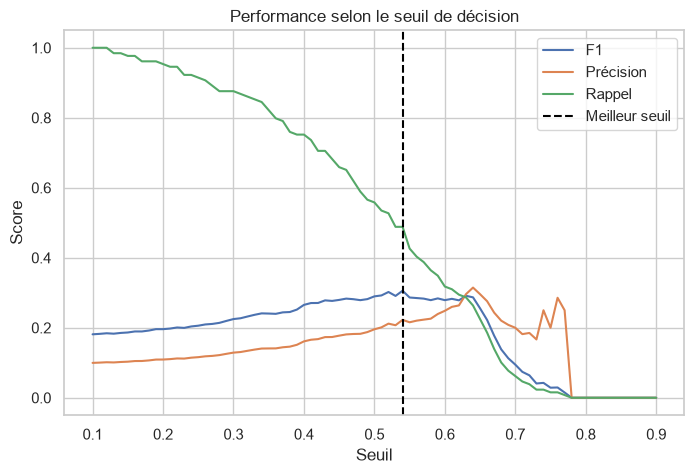

In [19]:
probabilites_validation = modele.predict_proba(X_validation)[:, 1]

resultats_seuils = []

for seuil in np.arange(0.10, 0.91, 0.01):
    predictions_seuil = (probabilites_validation >= seuil).astype(int)
    resultats_seuils.append({
        "seuil": round(float(seuil), 2),
        "f1": f1_score(y_validation, predictions_seuil),
        "precision": precision_score(y_validation, predictions_seuil, zero_division=0),
        "rappel": recall_score(y_validation, predictions_seuil, zero_division=0),
        "nombre_positifs_predits": predictions_seuil.sum()
    })

resultats_seuils = pd.DataFrame(resultats_seuils)
meilleure_ligne = resultats_seuils.loc[resultats_seuils["f1"].idxmax()]
meilleur_seuil = float(meilleure_ligne["seuil"])

print("Meilleur seuil :", meilleur_seuil)
print("Meilleur F1 :", round(meilleure_ligne["f1"], 4))
print("AUC validation :", round(roc_auc_score(y_validation, probabilites_validation), 4))

display(resultats_seuils.sort_values("f1", ascending=False).head(10))

plt.figure(figsize=(8, 5))
plt.plot(resultats_seuils["seuil"], resultats_seuils["f1"], label="F1")
plt.plot(resultats_seuils["seuil"], resultats_seuils["precision"], label="Précision")
plt.plot(resultats_seuils["seuil"], resultats_seuils["rappel"], label="Rappel")
plt.axvline(meilleur_seuil, color="black", linestyle="--", label="Meilleur seuil")
plt.title("Performance selon le seuil de décision")
plt.xlabel("Seuil")
plt.ylabel("Score")
plt.legend()
plt.show()

## 18. Évaluation détaillée

La précision indique la proportion de vrais départs parmi les départs prédits. Le rappel indique la proportion de vrais départs effectivement détectés. Le F1-score équilibre ces deux mesures.

              precision    recall  f1-score   support

           0     0.9360    0.8143    0.8709      1185
           1     0.2226    0.4884    0.3058       129

    accuracy                         0.7823      1314
   macro avg     0.5793    0.6514    0.5884      1314
weighted avg     0.8660    0.7823    0.8155      1314



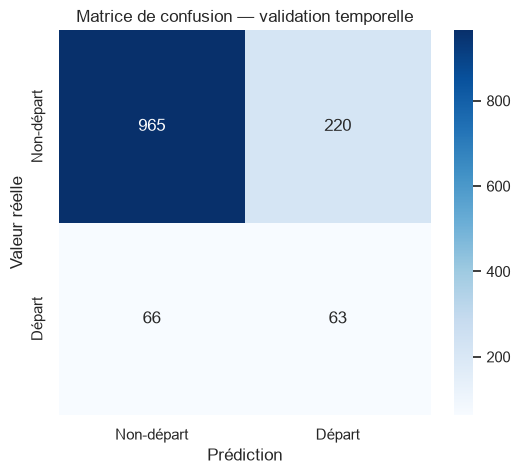

In [20]:
predictions_validation = (
    probabilites_validation >= meilleur_seuil
).astype(int)

print(classification_report(y_validation, predictions_validation, digits=4))

matrice = confusion_matrix(y_validation, predictions_validation)

plt.figure(figsize=(6, 5))
sns.heatmap(
    matrice,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-départ", "Départ"],
    yticklabels=["Non-départ", "Départ"]
)
plt.title("Matrice de confusion — validation temporelle")
plt.xlabel("Prédiction")
plt.ylabel("Valeur réelle")
plt.show()

## 19. Importance des variables

L’importance CatBoost permet d’identifier les variables les plus utilisées par le modèle. Elle ne prouve pas une relation causale, mais elle guide les prochaines expérimentations de feature engineering.

,variable,importance
48,ratio_salaire_reference,12.417512
12,engagement_actuel,11.962720
13,engagement_precedent,4.625203
36,anciennete,4.480328
35,age,4.467607
10,performance_actuelle,3.192851
11,performance_precedente,2.933998
2,departement,2.862517
34,source_sirh,2.790148
33,code_site,2.680884


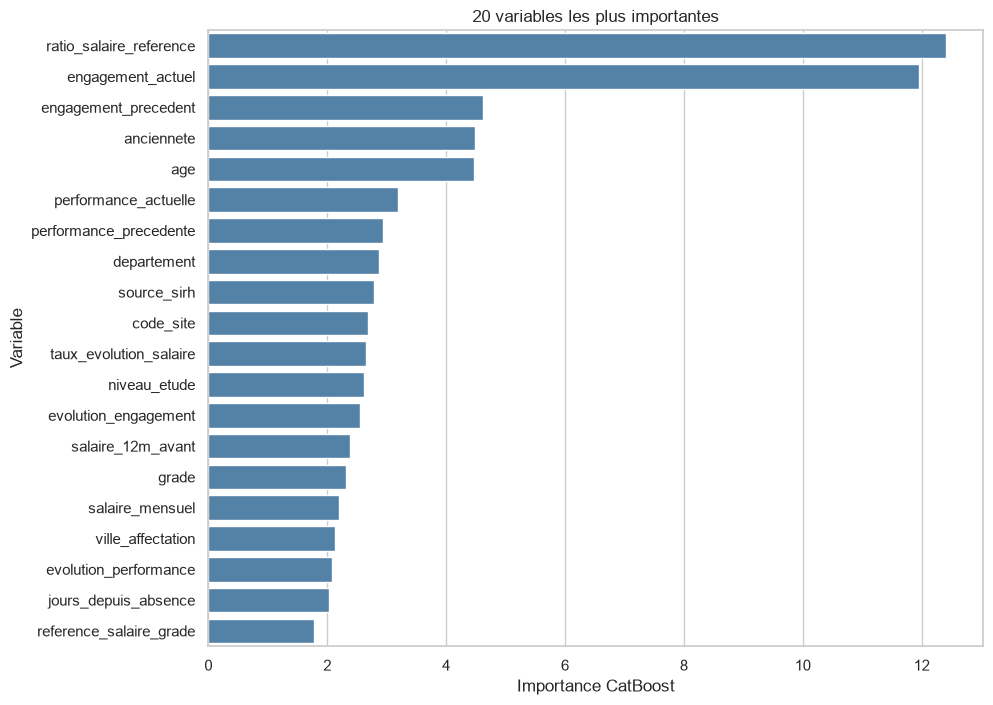

In [21]:
importance_variables = pd.DataFrame({
    "variable": X_train.columns,
    "importance": modele.get_feature_importance()
}).sort_values("importance", ascending=False)

display(importance_variables.head(25))

plt.figure(figsize=(10, 8))
sns.barplot(
    data=importance_variables.head(20),
    x="importance",
    y="variable",
    color="steelblue"
)
plt.title("20 variables les plus importantes")
plt.xlabel("Importance CatBoost")
plt.ylabel("Variable")
plt.show()

## 20. Réentraînement sur tout le train

Après l’évaluation, le modèle final est réentraîné sur toutes les périodes historiques. Le nombre d’itérations reprend la meilleure itération observée pendant la validation temporelle.

In [22]:
nombre_iterations_final = max(modele.get_best_iteration() + 1, 50)

modele_final = CatBoostClassifier(
    iterations=nombre_iterations_final,
    learning_rate=0.03,
    depth=6,
    loss_function="Logloss",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=100
)

modele_final.fit(
    X_complet,
    y_complet,
    cat_features=colonnes_categorielles
)

print("Nombre d'itérations du modèle final :", nombre_iterations_final)

0:	learn: 0.6889304	total: 39.2ms	remaining: 11.8s
100:	learn: 0.5788605	total: 4.27s	remaining: 8.5s
200:	learn: 0.5367529	total: 8.59s	remaining: 4.32s
300:	learn: 0.4926447	total: 12.9s	remaining: 42.9ms
301:	learn: 0.4919609	total: 13s	remaining: 0us
Nombre d'itérations du modèle final : 302


## 21. Création de la première soumission

Le modèle calcule les probabilités de départ du test. Le seuil choisi sur la validation temporelle transforme ces probabilités en classes `0` et `1`.

In [23]:
probabilites_test = modele_final.predict_proba(X_test)[:, 1]
predictions_test = (probabilites_test >= meilleur_seuil).astype(int)

soumission = pd.DataFrame({
    "id": test_prepare["id"],
    "prediction": predictions_test
})

CHEMIN_SOUMISSION = "../submissions/submission_catboost_temporelle_v1.csv"
soumission.to_csv(CHEMIN_SOUMISSION, index=False)

print("Fichier créé :", CHEMIN_SOUMISSION)
print("Nombre de départs prédits :", soumission["prediction"].sum())
print("Taux de départ prédit :", round(soumission["prediction"].mean() * 100, 2), "%")
display(soumission.head())

Fichier créé : ../submissions/submission_catboost_temporelle_v1.csv
Nombre de départs prédits : 350
Taux de départ prédit : 23.22 %


,id,prediction
0,OBS005445,0
1,OBS005446,0
2,OBS005447,1
3,OBS005448,0
4,OBS005449,1


## 22. Journal de l’expérience

Cette cellule résume l’expérience afin de comparer proprement les futures versions du modèle.

In [24]:
journal_experience = pd.DataFrame([{
    "experience": "CatBoost temporel v1",
    "periode_validation": "2024-06-30",
    "nombre_variables": X_train.shape[1],
    "meilleure_iteration": modele.get_best_iteration(),
    "seuil": meilleur_seuil,
    "auc_validation": roc_auc_score(y_validation, probabilites_validation),
    "f1_validation": f1_score(y_validation, predictions_validation),
    "precision_validation": precision_score(y_validation, predictions_validation, zero_division=0),
    "rappel_validation": recall_score(y_validation, predictions_validation, zero_division=0),
    "positifs_test": int(predictions_test.sum())
}])

display(journal_experience.T)

journal_experience.to_csv(
    "../reports/journal_experience_catboost_temporelle_v1.csv",
    index=False
)

,0
experience,CatBoost temporel v1
periode_validation,2024-06-30
nombre_variables,60
meilleure_iteration,301
seuil,0.54
auc_validation,0.710254
f1_validation,0.305825
precision_validation,0.222615
rappel_validation,0.488372
positifs_test,350


## Conclusion

Ce notebook fournit une première chaîne complète et reproductible : audit, visualisation, nettoyage, feature engineering, validation temporelle, optimisation du seuil et création de la soumission.

Les prochaines améliorations devront être comparées à cette baseline temporelle, notamment :

- encodages historiques par poste et département réalisés sans fuite de cible ;
- salaire relatif au poste, au grade et au département ;
- validation temporelle sur plusieurs fenêtres ;
- comparaison CatBoost, LightGBM et XGBoost ;
- assemblage des meilleurs modèles et choix du seuil à partir de prédictions hors échantillon.